# Variational AutoEncoder

Modificación de las secciones de Variational Autoencoder del cap. 17 de Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow, 3rd Edition https://learning.oreilly.com/library/view/hands-on-machine-learning/9781098125967/ch17.html#id329 y su correspondiente notebook. La modificación ha sido adaptar el código a Keras 3 ya que en el libro se usa el método add_loss() que en el código de Keras, en keras/models/functional.py, aparece así:<br>
    &emsp;def add_loss(self, loss):<br>
        &emsp;&emsp;# Symbolic only. TODO<br>
        &emsp;&emsp;raise NotImplementedError

Adaptado de https://keras.io/examples/generative/vae/, aquí usa CNN y como función de pérdida binary_crossentropy en lugar de mse, en este caso con mse los resultados son mucho mejores. El código está disponible en https://github.com/keras-team/keras-io/blob/master/examples/generative/vae.py.

Modificación layer sampling https://apxml.com/courses/autoencoders-representation-learning/chapter-4-variational-autoencoders-generative/implementing-vae-image-generation-practice. En el código original de Keras el layer sampling está dentro del encoder, en la modificación es un layer aparte. Sin embargo en ambos códigos las variables batch y dim de este layer toman sus tamaños de z_mean (en el libro codings_mean) y lo hemos cambiado para que lo hagan de z_log_var (en el libro codings_log_var), como ocurre en el código original del libro.

Se ha añadido la implementación de test_step() dentro de la definición de la clase VAE https://www.dataleadsfuture.com/implementing-the-train_step-method-in-keras-3-from-errors-to-solutions/#/portal para que al método fit() se le pueda mandar el parámetro validation_data.

Conviene consultar los enlaces anteriores ya que en ellos que se explica el código.

## Setup

In [1]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras
from keras import ops
from keras import layers

2026-03-10 10:45:24.736513: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
from tensorflow.python.client import device_lib
def get_available_gpus():
    local_device_protos = device_lib.list_local_devices()
    return [x.name for x in local_device_protos if x.device_type == 'GPU']

print("Available GPUs ")
get_available_gpus()

Available GPUs 


I0000 00:00:1773135932.515583   35542 gpu_device.cc:2020] Created device /device:GPU:0 with 7060 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


['/device:GPU:0']

## Create a sampling layer

In [3]:
class Sampling(layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(42)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        #batch = ops.shape(z_mean)[0]
        #dim = ops.shape(z_mean)[1]
        batch = ops.shape(z_log_var)[0]
        dim = ops.shape(z_log_var)[1]
        epsilon = keras.random.normal(shape=(batch, dim), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

## Build the encoder

In [4]:
tf.random.set_seed(42)  # extra code – ensures reproducibility on CPU

codings_size = 10
encoder_inputs = keras.layers.Input(shape=[28, 28])
x = layers.Flatten()(encoder_inputs)
x = layers.Dense(150, activation="relu")(x)
x = layers.Dense(100, activation="relu")(x)
z_mean = layers.Dense(codings_size, name="z_mean")(x)
z_log_var = layers.Dense(codings_size, name="z_log_var")(x)
variational_encoder = keras.Model([encoder_inputs], [z_mean, z_log_var], name="encoder")
variational_encoder.summary()

I0000 00:00:1773135932.544182   35542 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7060 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 784)       │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 150)       │    117,750 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 100)       │     15,100 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 10)        │      1,010 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 10)        │      1,010 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 134,870 (526.84 KB)

 Trainable params: 134,870 (526.84 KB)

 Non-trainable params: 0 (0.00 B)

## Build the decoder

In [5]:
latent_inputs = keras.layers.Input(shape=(codings_size,))
x = tf.keras.layers.Dense(100, activation="relu")(latent_inputs)
x = tf.keras.layers.Dense(150, activation="relu")(x)
x = tf.keras.layers.Dense(28 * 28)(x)
outputs = tf.keras.layers.Reshape([28, 28])(x)
variational_decoder = keras.Model(latent_inputs, outputs, name="decoder")
variational_decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │         1,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 150)            │        15,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       118,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,634 (525.91 KB)

 Trainable params: 134,634 (525.91 KB)

 Non-trainable params: 0 (0.00 B)

## Define the VAE as a `Model` with custom `train_step` and `test_step`

In [6]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.sampling = Sampling()
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            z_mean, z_log_var = self.encoder(x) # en el libro codings_mean y codings_log_var
            z = self.sampling([z_mean, z_log_var]) # en el libro codings
            reconstruction = self.decoder(z)
            # MSE loss
            reconstruction_loss = tf.keras.ops.mean(tf.keras.ops.square(x - reconstruction))
            kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
            kl_loss = ops.mean(ops.sum(kl_loss, axis=1))            
            total_loss = reconstruction_loss + tf.keras.ops.mean(kl_loss)/784.
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }
        
    def test_step(self, data): 
        X, y = data
        y_pred = self(X, training=False)
        
        for metric in self.metrics:
            metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}        
        
    def call(self, inputs, *args, **kwargs):
        # Used for inference/prediction
        z_mean, z_log_var = self.encoder(inputs)
        z = self.sampling([z_mean, z_log_var])
        return self.decoder(z)        

## Train the VAE

Let's load the fashion MNIST dataset, scale it, and split it into a training set, a validation set, and a test set:

In [7]:
fashion_mnist = keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

In [8]:
variational_ae = VAE(variational_encoder, variational_decoder)
variational_ae.compile(optimizer=keras.optimizers.Nadam())
history = variational_ae.fit(X_train, X_train, epochs=25, batch_size=128,
                             validation_data=(X_valid, X_valid))

Epoch 1/25


2026-03-10 10:46:23.038796: I external/local_xla/xla/service/service.cc:163] XLA service 0x2530dec0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-10 10:46:23.038809: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce GTX 1070, Compute Capability 6.1
2026-03-10 10:46:23.131514: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-03-10 10:46:23.432087: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


 78/430 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - kl_loss: 4.7836 - loss: 0.1192 - reconstruction_loss: 0.1131

I0000 00:00:1773135985.462494   40266 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


430/430 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - kl_loss: 7.0430 - loss: 0.0500 - reconstruction_loss: 0.0410 - val_kl_loss: 0.6193 - val_reconstruction_loss: 0.6193 - val_total_loss: 0.6193
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - kl_loss: 6.7014 - loss: 0.0364 - reconstruction_loss: 0.0278 - val_kl_loss: 0.6326 - val_reconstruction_loss: 0.6326 - val_total_loss: 0.6326
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - kl_loss: 6.5730 - loss: 0.0345 - reconstruction_loss: 0.0261 - val_kl_loss: 0.6403 - val_reconstruction_loss: 0.6403 - val_total_loss: 0.6403
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - kl_loss: 6.5661 - loss: 0.0336 - reconstruction_loss: 0.0252 - val_kl_loss: 0.6360 - val_reconstruction_loss: 0.6360 - val_total_loss: 0.6360
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - kl_loss: 6.6074 - loss: 0.0331 - reconstruction_loss: 0.0247 - val_kl_loss: 0.6357 - val_reconstruction_loss: 0.6357 - val_total_loss: 0.6357
Epoch 6/25
430/430 ━━━━━━━━━━━━

## Visualizing the Reconstructions

This function processes a few validation images through the autoencoder and displays the original images and their reconstructions:

In [9]:
def plot_reconstructions(model, images=X_valid, n_images=5):
    predictions = model.predict(images[:n_images])
    reconstructions = np.clip(predictions, 0, 1)
    fig = plt.figure(figsize=(n_images * 1.5, 3))
    for image_index in range(n_images):
        plt.subplot(2, n_images, 1 + image_index)
        plt.imshow(images[image_index], cmap="binary")
        plt.axis("off")
        plt.subplot(2, n_images, 1 + n_images + image_index)
        plt.imshow(reconstructions[image_index], cmap="binary")        
        plt.axis("off")

In [10]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [11]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "generative"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 681ms/step


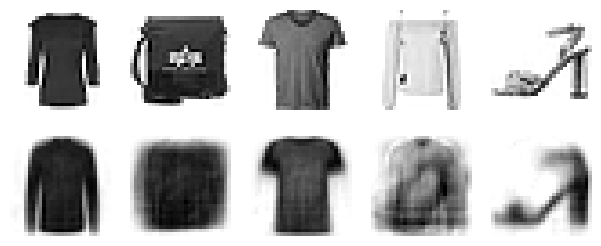

In [12]:
plot_reconstructions(variational_ae)
plt.show()

## Generate Fashion Images

Let's generate a few random codings and decode them:

In [13]:
tf.random.set_seed(42)  # extra code – ensures reproducibility on CPU

codings = keras.random.normal(shape=[3 * 7, codings_size])
images = variational_ae.decoder(codings).numpy()

Now let's plot these images:

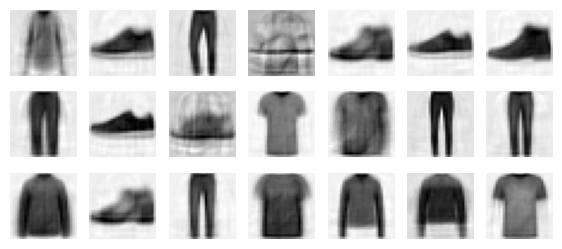

In [14]:
# extra code – this cells generates and saves Figure 17-12

def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = images.squeeze(axis=-1)
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="binary")
        plt.axis("off")

plot_multiple_images(images, 7)
save_fig("vae_generated_images_plot", tight_layout=False)
plt.show()

Now let's perform semantic interpolation between 2 images:

In [15]:
# Ha habido que cambiar el código original en el que se tenía
# codings = np.zeros([7, codings_size])
# codings[:, 3] = np.linspace(-0.8, 0.8, 7)
# para que el resultado similar al del notebook del libro
# con el original no hay variedad en las imágenes
tf.random.set_seed(42)

inter_steps = 7
codings = np.ones([inter_steps, codings_size])
values = np.linspace(-0.8, 0, inter_steps)
for i in range(inter_steps):
    codings[i, :] = codings[i, :] * values[i]

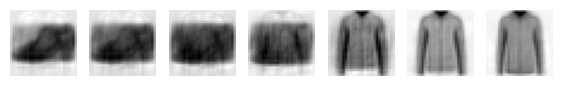

In [16]:
images = variational_ae.decoder(codings).numpy()
plot_multiple_images(images)
save_fig("semantic_interpolation_plot", tight_layout=False)
plt.show()